# Lesson 9.3: Bayesian and Frequentist Thinking: Two Ways to Learn from Data

Update a belief about a checkout page's conversion rate (14 buyers out of 40) with a Beta prior, get a 95% credible interval, and compare it with the usual confidence interval.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Prior, data and posterior

A Beta(a, b) prior acts like a past record of a successes and b failures. Beta(1, 1) is flat: every rate is equally plausible. After k buyers out of n, the posterior is simply Beta(a + k, b + n - k).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

a, b = 1, 1
k, n = 14, 40

post_a, post_b = a + k, b + n - k
posterior = stats.beta(post_a, post_b)

print(f'posterior = Beta({post_a}, {post_b})')
print(f'posterior mean = {posterior.mean():.3f}')

posterior = Beta(15, 27)
posterior mean = 0.357


## 2. Credible interval and a direct probability

A 95% credible interval takes the middle 95% of the posterior. We can also read off the probability that the new page beats the old 25% rate, which a p-value cannot give directly.

In [2]:
low, high = posterior.ppf([0.025, 0.975])
p_better = posterior.sf(0.25)

print(f'95% credible interval: {low:.3f} to {high:.3f}')
print(f'P(rate > 25%) = {p_better:.3f}')

95% credible interval: 0.221 to 0.506
P(rate > 25%) = 0.933


## 3. The frequentist answer for comparison

The usual approach tests the null value 25% and builds a confidence interval (Wilson). The numbers look alike, but the sentences mean different things: the confidence interval is about repeating the procedure, the credible interval about this rate.

In [3]:
from statsmodels.stats.proportion import proportion_confint

ci = proportion_confint(k, n, alpha=0.05, method='wilson')
se = np.sqrt(0.25 * 0.75 / n)
z = (k / n - 0.25) / se

print(f'Wilson 95% CI: {ci[0]:.3f} to {ci[1]:.3f}')
print(f'z = {z:.2f}, one-sided p = {stats.norm.sf(z):.3f}')

Wilson 95% CI: 0.221 to 0.505
z = 1.46, one-sided p = 0.072


## 4. Draw the prior and the posterior

The flat prior is a level line. The data pull the belief into a peak near 0.35, and the shaded band is the 95% credible interval. The dashed line marks the old page's 25% rate.

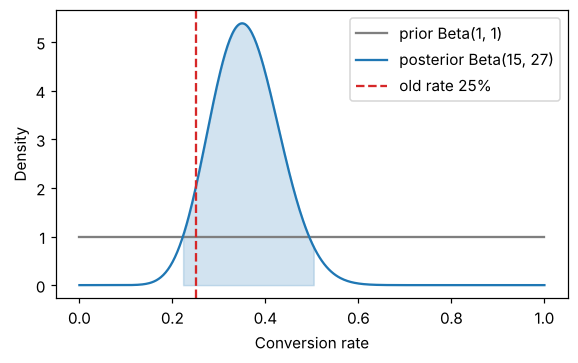

In [4]:
x = np.linspace(0, 1, 400)

plt.figure(figsize=(6, 3.4))
plt.plot(x, stats.beta(a, b).pdf(x), color='#7f7f7f', label='prior Beta(1, 1)')
plt.plot(x, posterior.pdf(x), color='#1f77b4', label=f'posterior Beta({post_a}, {post_b})')
mid = (x >= low) & (x <= high)
plt.fill_between(x[mid], posterior.pdf(x[mid]), color='#1f77b4', alpha=0.2)
plt.axvline(0.25, color='#d62728', linestyle='--', label='old rate 25%')
plt.xlabel('Conversion rate')
plt.ylabel('Density')
plt.legend()
plt.show()

## Try this

- Use the sceptical prior Beta(5, 15): set a, b = 5, 15 and rerun. Predict whether P(rate > 25%) goes up or down.
- Use 140 buyers out of 400 (the same 35%). Predict what happens to the width of the credible interval and to the effect of the prior.

## The same idea in R, SPSS and Stata

**R**

```r
qbeta(c(0.025, 0.975), 15, 27)
1 - pbeta(0.25, 15, 27)
15 / (15 + 27)
prop.test(14, 40, correct = FALSE)$conf.int
prop.test(14, 40, p = 0.25, alternative = "greater", correct = FALSE)$p.value
```

**SPSS** (SPSS has no standard menu for Bayesian proportions, so use Transform > Compute Variable with the IDF.BETA and CDF.BETA functions)

```
DATA LIST FREE / dummy.
BEGIN DATA
1
END DATA.
COMPUTE lower = IDF.BETA(0.025, 15, 27).
COMPUTE upper = IDF.BETA(0.975, 15, 27).
COMPUTE p_better = 1 - CDF.BETA(0.25, 15, 27).
COMPUTE z = (0.35 - 0.25) / SQRT(0.25 * 0.75 / 40).
COMPUTE p_onesided = 1 - CDF.NORMAL(z, 0, 1).
FORMATS lower upper p_better z p_onesided (F8.4).
LIST lower upper p_better z p_onesided.
```

**Stata**

```
display "posterior mean = " 15 / 42
display "lower 95% = " invibeta(15, 27, 0.025)
display "upper 95% = " invibeta(15, 27, 0.975)
display "P(rate > 0.25) = " 1 - ibeta(15, 27, 0.25)
cii proportions 40 14, wilson
prtesti 40 14 0.25
```